# Entire Place or Room? Classifying Sri Lankan Airbnb Listings
### ML Lecture 7 Class Activity: Random Forest vs XGBoost (+ Soft Voting and Stacking)

**Student:** _your name_ &nbsp;|&nbsp; **Index no:** _your index_

---

## 1. Problem

Sri Lanka's tourism recovery has brought thousands of small hosts online: villas in Galle, homestays in Ella and Jaffna, boutique hotels in Colombo. Many of these listings are also posted on **ikman.lk, Facebook groups and WhatsApp**, where hosts only write a title and a guest count and never say *what* is being rented.

For a guest, "Sea View Villa – Mirissa" could mean the whole villa or one room in it. That difference changes the price, privacy and who the listing suits (families vs couples).

**Task (binary classification):** given only what a host typically writes, meaning the **listing title**, the **number of guests** and (if it has one) the **star rating**, predict whether the listing is:

* **1 = Entire place** (whole villa, home, apartment, bungalow …)
* **0 = Room** (private room, hotel or guesthouse room, shared room)

A local aggregator could use this model to auto-tag listings scraped from classified sites, or warn a host when their title is ambiguous.

## 2. Dataset (local, Sri Lankan)

**"Destination Sri Lanka"**, Kaggle (user *kanchana1990*): about 5,000 accommodations across Sri Lanka, sourced from Airbnb plus the author's personal contacts.

| Column | Meaning |
|---|---|
| `name` | Listing title written by the host |
| `numberOfGuests` | Maximum guests allowed (Airbnb caps the field at 16) |
| `roomType` | Airbnb property type (83 distinct values), **used to build the target** |
| `stars` | Average guest rating (missing for listings with no reviews yet) |

In [1]:
# In Google Colab, xgboost is already installed. Uncomment if running elsewhere:
# !pip install -q xgboost scikit-learn pandas matplotlib seaborn

import time, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RandomizedSearchCV, cross_val_score)
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, classification_report)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 60)

### Feature-engineering module
The feature code lives in its own file, `features.py`, so that **the notebook, the pickled model and the front-end app all build features in exactly the same way**. (A pickle stores a *reference* to the class, so the app must be able to import the same module.) The cell below writes that file.

In [2]:
%%writefile features.py
"""
Feature engineering for Sri Lankan Airbnb listings.

The raw dataset only has a free-text title (`name`), `numberOfGuests` and
`stars`. Everything else the models use is derived here from the title,
using local knowledge of how Sri Lankan hosts write listings and where
the tourist areas are.

Both the notebook and the front end import this file, so the pickled model
and the app always build features the same way.
"""
import re

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

# --------------------------------------------------------------------------
# Sri Lankan tourist regions, matched against the listing title.
# Order matters: the first region that matches wins.
# --------------------------------------------------------------------------
REGIONS = {
    "Colombo & suburbs": [
        "colombo", "havelock", "mount lavinia", "dehiwala", "nugegoda",
        "kotte", "battaramulla", "rajagiriya", "boralesgamuwa", "wellawatte",
        "bambalapitiya", "kollupitiya", "maharagama", "moratuwa", "malabe",
    ],
    "South coast": [
        "galle", "unawatuna", "mirissa", "weligama", "ahangama", "hikkaduwa",
        "bentota", "tangalle", "hiriketiya", "koggala", "talpe", "midigama",
        "madiha", "matara", "dikwella", "kalutara", "beruwala", "induruwa",
        "ambalangoda", "habaraduwa", "polhena", "talalla", "dickwella",
        "kabalana", "thalpe", "aluthgama", "balapitiya", "kosgoda",
    ],
    "Hill country": [
        "kandy", "ella", "nuwara eliya", "haputale", "bandarawela", "hatton",
        "knuckles", "kitulgala", "badulla", "nuwara", "eliya", "adams peak",
        "nallathanniya", "kandapola", "peradeniya", "gampola", "tea estate",
    ],
    "Cultural triangle": [
        "sigiriya", "dambulla", "habarana", "anuradhapura", "polonnaruwa",
        "matale", "kandalama", "kurunegala",
    ],
    "North & East": [
        "jaffna", "trincomalee", "trinco", "nilaveli", "arugam", "pasikudah",
        "batticaloa", "kalkudah", "uppuveli", "nallur", "mannar", "pottuvil",
    ],
    "West coast & airport": [
        "negombo", "airport", "katunayake", "kalpitiya", "wattala", "ja-ela",
        "chilaw", "marawila", "waikkal",
    ],
    "Wildlife & safari": [
        "yala", "udawalawe", "tissa", "kirinda", "tissamaharama", "wilpattu",
        "minneriya", "kataragama", "safari",
    ],
}

# --------------------------------------------------------------------------
# Keyword groups. Each becomes a 0/1 feature.
# --------------------------------------------------------------------------
KEYWORDS = {
    # Words that describe a single room inside a bigger property
    "kw_room": r"\b(room|rooms|chamber|chambre|zimmer|ensuite|en-suite)\b",
    "kw_bed_type": r"\b(double|twin|triple|single|king|queen|dbl|quad|family room)\b",
    "kw_room_grade": r"\b(deluxe|superior|standard|executive|economy|premier)\b",
    # Words that describe a whole property
    "kw_whole_property": (
        r"\b(villa|villas|house|home|bungalow|cottage|apartment|apt|condo|"
        r"entire|penthouse|chalet|loft|residence|whole|cabin|townhouse|"
        r"maison|haus|flat)\b"
    ),
    "kw_bedrooms": r"\b(\d+\s*(br|bed|beds|bedroom|bedrooms|bhk))\b|\bbedrooms?\b",
    # Words for hotel-style businesses that rent rooms
    "kw_hotel_business": (
        r"\b(hotel|resort|boutique|inn|lodge|hostel|guesthouse|guest house|"
        r"homestay|home stay|b&b|bnb|bed and breakfast|motel)\b"
    ),
    "kw_suite": r"\b(suite|suites)\b",
    "kw_cabana": r"\b(cabana|cabanas|hut|tent|glamping|treehouse|tree house)\b",
    # Amenities / selling points
    "kw_pool": r"\b(pool|infinity|jacuzzi|swimming)\b",
    "kw_luxury": r"\b(luxury|luxurious|luxe|premium|exclusive|grand|royal)\b",
    "kw_beach": r"\b(beach|beachfront|sea|ocean|seaview|surf|bay|lagoon)\b",
    "kw_nature": r"\b(nature|jungle|forest|garden|river|lake|eco|paddy|mountain|hill|hills|tea)\b",
    "kw_kitchen": r"\b(kitchen|kitchenette|self catering|self-catering|fully furnished|furnished)\b",
    "kw_breakfast": r"\b(breakfast|half board|full board|meals|chef)\b",
    "kw_ac": r"\b(ac|a/c|air conditioned|air-conditioned|aircon)\b",
    "kw_budget": r"\b(budget|cheap|affordable|economy|backpacker)\b",
    "kw_family": r"\b(family|group|groups|sleeps)\b",
}

FOREIGN_WORDS = r"\b(chambre|maison|vacances|avec|proche|zimmer|haus|mit|casa|camera|habitaci[oó]n)\b"

NUMERIC_FEATURES = (
    ["numberOfGuests", "stars", "bedrooms_in_title", "title_length",
     "title_words", "title_has_number", "title_foreign_language"]
    + list(KEYWORDS)
)
CATEGORICAL_FEATURES = ["region"]


def find_region(title: str) -> str:
    t = title.lower()
    for region, places in REGIONS.items():
        for place in places:
            if re.search(r"\b" + re.escape(place) + r"\b", t):
                return region
    return "Unknown"


def bedrooms_from_title(title: str) -> float:
    """'Cozy 2 BR apartment' -> 2.0. Returns NaN when the title has no count."""
    m = re.search(r"(\d+)\s*-?\s*(br|bed|beds|bedroom|bedrooms|bhk|bdr)\b", title.lower())
    if m:
        n = float(m.group(1))
        return n if 0 < n <= 15 else np.nan
    words = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5, "six": 6}
    m = re.search(r"\b(one|two|three|four|five|six)\s*-?\s*(br|bed|beds|bedroom|bedrooms)\b", title.lower())
    if m:
        return float(words[m.group(1)])
    return np.nan


def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """Turn raw columns (name, numberOfGuests, stars) into model features."""
    df = df.copy()
    title = df["name"].fillna("").astype(str)
    low = title.str.lower()

    out = pd.DataFrame(index=df.index)
    out["numberOfGuests"] = pd.to_numeric(df["numberOfGuests"], errors="coerce")
    # stars stays NaN for unrated listings; the pipeline imputes it
    out["stars"] = pd.to_numeric(df.get("stars", np.nan), errors="coerce")
    out["bedrooms_in_title"] = title.apply(bedrooms_from_title)
    out["title_length"] = title.str.len()
    out["title_words"] = title.str.split().str.len().fillna(0)
    out["title_has_number"] = title.str.contains(r"\d", regex=True).astype(int)
    out["title_foreign_language"] = low.apply(lambda t: int(bool(re.search(FOREIGN_WORDS, t))))
    for name, pattern in KEYWORDS.items():
        out[name] = low.apply(lambda t, p=pattern: int(bool(re.search(p, t))))
    out["region"] = title.apply(find_region)
    return out[NUMERIC_FEATURES + CATEGORICAL_FEATURES]


class FeatureBuilder(BaseEstimator, TransformerMixin):
    """sklearn wrapper so feature engineering is saved inside the pipeline/pickle."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return engineer_features(X)


def room_type_group(room_type: str) -> str:
    """Collapse Airbnb's 83 room types into 5 groups."""
    r = str(room_type).lower()
    if r.startswith("entire") or r in ("tiny home", "earthen home", "casa particular", "cycladic home"):
        return "Entire place"
    if r.startswith("private room"):
        return "Private room"
    if r.startswith("room in"):
        return "Hotel-style room"
    if r.startswith("shared room"):
        return "Shared room"
    return "Unique stay"

Overwriting features.py


In [3]:
import importlib, features
importlib.reload(features)
from features import (FeatureBuilder, engineer_features, room_type_group,
                      NUMERIC_FEATURES, CATEGORICAL_FEATURES, REGIONS)

## 3. Load and inspect the data

In [4]:
df_raw = pd.read_csv("airbnb_plus_personal_contacts.csv", encoding="utf-8-sig")
print("Shape:", df_raw.shape)
df_raw.head(10)

Shape: (5000, 4)


,name,numberOfGuests,roomType,stars
0,D'Villa Garden House,2,Private room in guest suite,4.61
1,"Suppar villa, a vacation home",6,Entire home,4.50
2,Relaxing 2 BR home closer to Nallur temple,4,Entire vacation home,NaN
3,Brinthavanam days inn /Non Ac/Free Veg Break fast,2,Private room in guesthouse,4.44
4,Lone Star Residence,6,Entire home,NaN
5,Valli Farm Stay with a view and fun Activities,3,Farm stay,NaN
6,SATK INN - Deluxe Family Room,3,Room in hotel,NaN
7,One bedroom apartment,3,Private room in condo,NaN
8,Charming 1 Cabana Resort with Pool,4,Private room in resort,NaN
9,"""Mathura"" Home / Two rooms for rental in Jaffna",4,Entire home,4.00


In [5]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   name            5000 non-null   str    
 1   numberOfGuests  5000 non-null   int64  
 2   roomType        5000 non-null   str    
 3   stars           2057 non-null   float64
dtypes: float64(1), int64(1), str(2)
memory usage: 397.0 KB


### 3.1 Null detection, duplicates and value ranges

In [6]:
nulls = df_raw.isna().sum().to_frame("missing")
nulls["% missing"] = (nulls["missing"] / len(df_raw) * 100).round(1)
display(nulls)

print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Distinct roomType values:", df_raw["roomType"].nunique())
display(df_raw[["numberOfGuests", "stars"]].describe().T)

,missing,% missing
name,0,0.0
numberOfGuests,0,0.0
roomType,0,0.0
stars,2943,58.9


Exact duplicate rows: 46
Distinct roomType values: 83


,count,mean,std,min,25%,50%,75%,max
numberOfGuests,5000.0,4.985800,3.563838,1.00,2.00,4.00,6.0,16.0
stars,2057.0,4.791561,0.249425,2.33,4.67,4.86,5.0,5.0


In [7]:
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"After dropping exact duplicates: {len(df)} rows ({len(df_raw) - len(df)} removed)")

After dropping exact duplicates: 4954 rows (46 removed)


**What the checks show**

* **`stars` is missing for ~59% of listings.** On Airbnb a rating only appears after a listing has enough reviews, so a missing rating mostly means *a new or rarely booked listing*. The missingness itself carries information, so it should be imputed **and flagged**, not dropped.
* `name`, `numberOfGuests` and `roomType` have no nulls.
* Exact duplicate rows (same title, guests, type and rating) are removed so the same listing cannot appear in both the training and the test set.
* `numberOfGuests` runs 1–16; 16 is Airbnb's cap ("16+"), not an error, so no outlier removal is needed.
* Ratings are heavily skewed toward 5.0 (median ≈ 4.86), which is typical of Airbnb.

### 3.2 Exploratory analysis

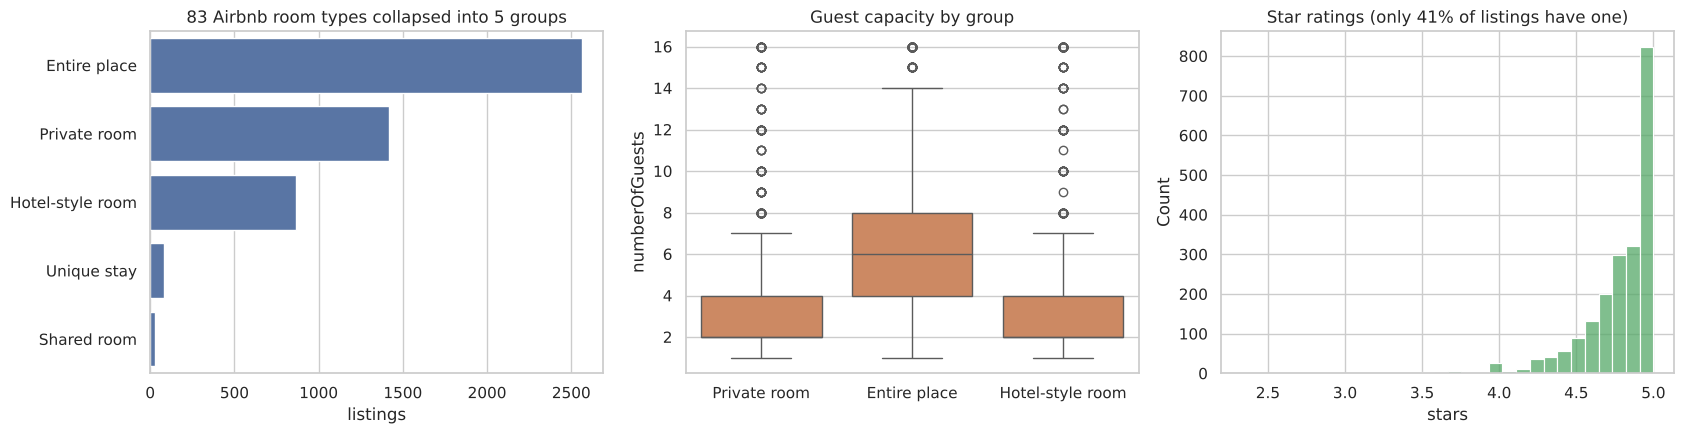

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
Entire place,2561.0,6.22,3.39,1.0,4.0,6.0,8.00,16.0
Hotel-style room,866.0,4.09,3.91,1.0,2.0,2.0,4.00,16.0
Private room,1417.0,3.43,2.83,1.0,2.0,2.0,4.00,16.0
Shared room,26.0,4.19,4.12,1.0,1.0,3.5,4.75,16.0
Unique stay,84.0,4.10,2.60,1.0,2.0,3.5,5.00,12.0


In [8]:
df["group"] = df["roomType"].map(room_type_group)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
order = df["group"].value_counts().index
sns.countplot(data=df, y="group", order=order, ax=axes[0], color="#4C72B0")
axes[0].set_title("83 Airbnb room types collapsed into 5 groups")
axes[0].set_xlabel("listings"); axes[0].set_ylabel("")

sns.boxplot(data=df[df.group.isin(["Entire place", "Private room", "Hotel-style room"])],
            x="group", y="numberOfGuests", ax=axes[1], color="#DD8452")
axes[1].set_title("Guest capacity by group"); axes[1].set_xlabel("")

sns.histplot(df["stars"].dropna(), bins=30, ax=axes[2], color="#55A868")
axes[2].set_title(f"Star ratings (only {df.stars.notna().mean():.0%} of listings have one)")
plt.tight_layout(); plt.show()

display(df.groupby("group")["numberOfGuests"].describe().round(2))

## 4. Choosing the prediction target

Because the dataset has **no price column**, the two candidate targets were:

1. **"Top-rated" listing** (stars ≥ 4.9). Useful to hosts, but only 41% of rows have a rating to learn from.
2. **Entire place vs room**, available for every row.

Before committing, both were tested quickly with the *same* features and an untuned Random Forest (5-fold cross-validated ROC-AUC; 0.5 means random guessing):

In [9]:
quick_rf = Pipeline([
    ("features", FeatureBuilder()),
    ("prep", ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES)])),
    ("model", RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                     random_state=RANDOM_STATE, n_jobs=-1))])
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rated = df[df["stars"].notna()]
y_top = (rated["stars"] >= 4.9).astype(int)
X_top = rated[["name", "numberOfGuests"]].assign(stars=np.nan)   # rating can't be a feature of itself
auc_top = cross_val_score(quick_rf, X_top, y_top, cv=cv5, scoring="roc_auc")

sub = df[df.group != "Unique stay"]
y_ent = (sub["group"] == "Entire place").astype(int)
auc_ent = cross_val_score(quick_rf, sub[["name", "numberOfGuests", "stars"]], y_ent,
                          cv=cv5, scoring="roc_auc")

pd.DataFrame({
    "target": ["Top-rated (stars ≥ 4.9)", "Entire place vs room"],
    "rows usable": [len(rated), len(sub)],
    "CV ROC-AUC": [f"{auc_top.mean():.3f} ± {auc_top.std():.3f}",
                   f"{auc_ent.mean():.3f} ± {auc_ent.std():.3f}"]})

,target,rows usable,CV ROC-AUC
0,Top-rated (stars ≥ 4.9),2054,0.578 ± 0.015
1,Entire place vs room,4870,0.892 ± 0.012


**Decision:** a listing's title and size say very little about how happy guests will be (that depends on cleanliness, the host and the location), so the rating target is barely better than chance. The **entire place vs room** target has strong, learnable signal and can be scored for every listing, so it is the target used from here on.

*Excluded rows:* the "Unique stay" group (treehouses, tents, huts, domes, boats …) is excluded because these can be either a whole unit or a shared site and do not belong cleanly to either class.

In [10]:
data = df[df["group"] != "Unique stay"].reset_index(drop=True)
data["target"] = (data["group"] == "Entire place").astype(int)
print(f"Rows used: {len(data)}  (dropped {len(df) - len(data)} unique-stay rows)")
print(data["target"].value_counts().rename({1: "Entire place (1)", 0: "Room (0)"}))
print(f"Positive rate: {data.target.mean():.1%}, so the classes are almost balanced")

Rows used: 4870  (dropped 84 unique-stay rows)
target
Entire place (1)    2561
Room (0)            2309
Name: count, dtype: int64
Positive rate: 52.6%, so the classes are almost balanced


## 5. Feature engineering from the listing title

The raw data has only one free-text column, so most of the signal has to be extracted from the **title**, using knowledge of how Sri Lankan hosts write listings:

| Feature | How it's built | Why it should help |
|---|---|---|
| `kw_room`, `kw_bed_type`, `kw_room_grade` | "room", "double/twin/triple", "deluxe/superior/standard" | Hotel and guesthouse rooms are sold by bed type and grade |
| `kw_whole_property` | villa, house, home, bungalow, apartment, condo, cottage … | Words for a whole property |
| `kw_bedrooms`, `bedrooms_in_title` | "2 BR", "3 bedroom villa" → 2, 3 | Only whole places advertise a bedroom count |
| `kw_hotel_business` | hotel, resort, boutique, inn, guesthouse, homestay, B&B | Businesses that rent rooms |
| amenity flags | pool, luxury, beach/sea, nature/tea/paddy, kitchen, breakfast, AC, budget, family | Kitchens suggest self-catering whole units; breakfast suggests a B&B room |
| `region` | Title matched against ~100 Sri Lankan place names → 7 tourist regions + Unknown | South-coast villas vs Colombo apartments vs Ella guesthouses |
| `title_length`, `title_words`, `title_has_number`, `title_foreign_language` | Text statistics; French/German titles | Room titles are often short ("Deluxe Double Room") |
| `numberOfGuests` | raw | Rooms sleep 2–3; villas sleep 6–16 |
| `stars` | raw, **NaN for unrated listings** | Imputed in the pipeline (see §6) |

In [11]:
X_all = data[["name", "numberOfGuests", "stars"]]
y_all = data["target"]

feat_preview = engineer_features(X_all)
display(pd.concat([X_all["name"], feat_preview], axis=1).head(8))

print("\nRegion detected from title:")
print(feat_preview["region"].value_counts())

missing = feat_preview.isna().mean().mul(100).round(1)
print("\nMissing values in engineered features (%):")
print(missing[missing > 0])

,name,numberOfGuests,stars,bedrooms_in_title,title_length,title_words,title_has_number,title_foreign_language,kw_room,kw_bed_type,...,kw_pool,kw_luxury,kw_beach,kw_nature,kw_kitchen,kw_breakfast,kw_ac,kw_budget,kw_family,region
0,D'Villa Garden House,2,4.61,NaN,20,3,0,0,0,0,...,0,0,0,1,0,0,0,0,0,Unknown
1,"Suppar villa, a vacation home",6,4.50,NaN,29,5,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Unknown
2,Relaxing 2 BR home closer to Nallur temple,4,NaN,2.0,42,8,1,0,0,0,...,0,0,0,0,0,0,0,0,0,North & East
3,Brinthavanam days inn /Non Ac/Free Veg Break fast,2,4.44,NaN,49,8,0,0,0,0,...,0,0,0,0,0,0,1,0,0,Unknown
4,Lone Star Residence,6,NaN,NaN,19,3,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Unknown
5,SATK INN - Deluxe Family Room,3,NaN,NaN,29,6,0,0,1,1,...,0,0,0,0,0,0,0,0,1,Unknown
6,One bedroom apartment,3,NaN,1.0,21,3,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Unknown
7,Charming 1 Cabana Resort with Pool,4,NaN,NaN,34,6,1,0,0,0,...,1,0,0,0,0,0,0,0,0,Unknown



Region detected from title:
region
Unknown                 3423
South coast              741
Hill country             228
Colombo & suburbs        197
North & East              84
West coast & airport      71
Wildlife & safari         68
Cultural triangle         58
Name: count, dtype: int64

Missing values in engineered features (%):
stars                58.5
bedrooms_in_title    90.2
dtype: float64


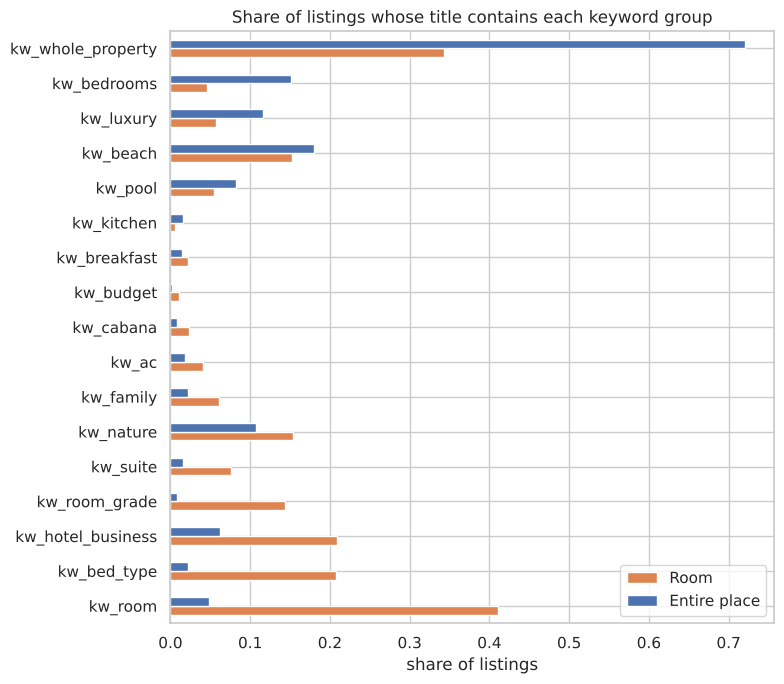

In [12]:
# Which title words separate the two classes? (share of each class whose title has the flag)
kw_cols = [c for c in feat_preview.columns if c.startswith("kw_")]
kw_rates = feat_preview[kw_cols].groupby(y_all.values).mean().T
kw_rates.columns = ["Room", "Entire place"]
kw_rates["difference"] = kw_rates["Entire place"] - kw_rates["Room"]
kw_rates.sort_values("difference").plot.barh(y=["Room", "Entire place"], figsize=(8, 7),
                                               color=["#DD8452", "#4C72B0"])
plt.title("Share of listings whose title contains each keyword group")
plt.xlabel("share of listings"); plt.tight_layout(); plt.show()

## 6. Preprocessing pipeline

| Step | Applied to | Choice and reason |
|---|---|---|
| **Imputation** | `stars` (≈59% missing), `bedrooms_in_title` (≈90% missing) | `SimpleImputer(strategy="median", add_indicator=True)`. Median because ratings are skewed toward 5.0 (the mean would be pulled down by a few low ratings). `add_indicator=True` adds a "was missing" column, because *unrated* and *no bedroom count in title* are themselves informative. |
| **Scaling** | all numeric features | `StandardScaler`. Tree models do not need scaling (splits are rank-based), but the **logistic-regression meta-learner** in the stacking model does, and keeping one shared pipeline means the front end never has to scale anything by hand. |
| **Encoding** | `region` | `OneHotEncoder(handle_unknown="ignore")`, so a region never seen in training does not crash the app. |
| **Transformations** | `numberOfGuests` | A log transform was considered, but trees are invariant to monotonic transformations, so it would not change the splits. Left as-is. |

Everything, from feature engineering through to the model, is **one sklearn `Pipeline`**, so the imputer's median and the scaler's mean and std are learned **only from training folds** (no data leakage) and the whole thing is saved into one `.pkl`.

### 6.1 Hold out one listing for inference, then train/test split

In [13]:
# Step 6 of the brief: keep ONE data point completely out of training and testing
holdout_idx = data.sample(1, random_state=7).index
holdout = data.loc[holdout_idx]
X_rest, y_rest = X_all.drop(holdout_idx), y_all.drop(holdout_idx)

X_train, X_test, y_train, y_test = train_test_split(
    X_rest, y_rest, test_size=0.20, stratify=y_rest, random_state=RANDOM_STATE)

print(f"Held-out inference sample: 1 row | train: {len(X_train)} | test: {len(X_test)}")
print(f"Entire-place share  train: {y_train.mean():.3f}  test: {y_test.mean():.3f}")
holdout[["name", "numberOfGuests", "stars", "roomType"]]

Held-out inference sample: 1 row | train: 3895 | test: 974
Entire-place share  train: 0.526  test: 0.526


,name,numberOfGuests,stars,roomType
3477,Kirinuga Boutique Retreat | Private room,2,4.71,Room in boutique hotel


In [14]:
def make_preprocessor():
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer([
        ("num", numeric, NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ])

def make_pipeline(model):
    return Pipeline([("features", FeatureBuilder()),
                     ("prep", make_preprocessor()),
                     ("model", model)])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 7. Parameter engineering (no default parameters)

The approach: **(1)** design a starting configuration from what the data looks like, **(2)** define a *narrow* search space around it, and **(3)** let 5-fold cross-validation on the training set choose within that space. The test set is never used for tuning.

### 7.1 Random Forest design

| Parameter | sklearn default | Designed value / range | Reasoning |
|---|---|---|---|
| `n_estimators` | 100 | **300–600** | More trees only reduce variance (they cannot overfit), and the data is small, so a few hundred trees cost little. |
| `max_depth` | None (fully grown) | **8–20** | Fully grown trees on ~3,900 rows with near-unique text features would memorise titles. A depth cap limits variance. |
| `min_samples_leaf` | 1 | **2–8** | Every leaf must cover several listings, so a rule like "title contains *Koggala*" can't be learned from one villa. |
| `max_features` | "sqrt" | **"sqrt", 0.3, 0.5** | The keyword flags are correlated (e.g. *villa* and *pool*). Fewer features per split de-correlates the trees. |
| `class_weight` | None | **"balanced"** | The classes are 53/47, nearly balanced, but this keeps recall on rooms honest. |
| `max_samples` | None | **0.7–0.9** | Each tree sees a smaller bootstrap sample, giving more diverse trees and a slight extra regularisation. |
| `criterion` | "gini" | **"gini", "entropy"** | Let CV decide. |

In [15]:
rf_search = RandomizedSearchCV(
    make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
    param_distributions={
        "model__n_estimators":     [300, 400, 500, 600],
        "model__max_depth":        [8, 10, 12, 15, 20],
        "model__min_samples_leaf": [2, 3, 5, 8],
        "model__max_features":     ["sqrt", 0.3, 0.5],
        "model__class_weight":     ["balanced"],
        "model__max_samples":      [0.7, 0.8, 0.9],
        "model__criterion":        ["gini", "entropy"],
    },
    n_iter=25, scoring="roc_auc", cv=cv, random_state=RANDOM_STATE, n_jobs=-1)

t0 = time.time(); rf_search.fit(X_train, y_train); rf_tune_time = time.time() - t0
print(f"Search took {rf_tune_time:.0f}s | best CV ROC-AUC = {rf_search.best_score_:.4f}")
rf_best_params = {k.replace("model__", ""): v for k, v in rf_search.best_params_.items()}
rf_best_params

Search took 159s | best CV ROC-AUC = 0.8912


{'n_estimators': 500,
 'min_samples_leaf': 2,
 'max_samples': 0.8,
 'max_features': 'sqrt',
 'max_depth': 12,
 'criterion': 'gini',
 'class_weight': 'balanced'}

### 7.2 XGBoost design

| Parameter | XGBoost default | Designed value / range | Reasoning |
|---|---|---|---|
| `learning_rate` (eta) | 0.3 | **0.03–0.1** | A small step size with more trees generalises better than a few big steps; 0.3 is aggressive for 3,900 rows. |
| `n_estimators` | 100 | **300–800** | Paired with the low learning rate (lower eta needs more rounds). |
| `max_depth` | 6 | **3–5** | Boosting builds many *shallow* trees that each fix the previous errors. Depth 3–5 captures 2- to 4-way interactions (e.g. *villa* + *6 guests* + *South coast*) without memorising. |
| `min_child_weight` | 1 | **1–5** | Minimum hessian (≈ number of samples) per leaf, the boosting counterpart of `min_samples_leaf`. |
| `subsample` | 1.0 | **0.7–0.9** | Row sampling per tree (stochastic gradient boosting), which reduces overfitting. |
| `colsample_bytree` | 1.0 | **0.6–0.9** | Feature sampling per tree. Helps because the keyword flags overlap. |
| `gamma` | 0 | **0–0.3** | Minimum loss reduction needed to make a split; prunes splits that do not help. |
| `reg_lambda` | 1 | **1–5** | L2 penalty on leaf weights. |
| `eval_metric` | — | **logloss** | The quantity the boosting minimises; matches the probabilistic output the front end shows. |

In [16]:
xgb_search = RandomizedSearchCV(
    make_pipeline(XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1)),
    param_distributions={
        "model__n_estimators":     [300, 500, 800],
        "model__learning_rate":    [0.03, 0.05, 0.1],
        "model__max_depth":        [3, 4, 5],
        "model__min_child_weight": [1, 3, 5],
        "model__subsample":        [0.7, 0.8, 0.9],
        "model__colsample_bytree": [0.6, 0.75, 0.9],
        "model__gamma":            [0, 0.1, 0.3],
        "model__reg_lambda":       [1, 3, 5],
    },
    n_iter=30, scoring="roc_auc", cv=cv, random_state=RANDOM_STATE, n_jobs=-1)

t0 = time.time(); xgb_search.fit(X_train, y_train); xgb_tune_time = time.time() - t0
print(f"Search took {xgb_tune_time:.0f}s | best CV ROC-AUC = {xgb_search.best_score_:.4f}")
xgb_best_params = {k.replace("model__", ""): v for k, v in xgb_search.best_params_.items()}
xgb_best_params

Search took 78s | best CV ROC-AUC = 0.8899


{'subsample': 0.8,
 'reg_lambda': 5,
 'n_estimators': 300,
 'min_child_weight': 1,
 'max_depth': 4,
 'learning_rate': 0.03,
 'gamma': 0.1,
 'colsample_bytree': 0.9}

## 8. Ensembles: soft voting (lecturer's notebook) and stacking (optional extension)

* **Soft voting** averages the two models' predicted probabilities. It works best when the models are similarly accurate but make *different* mistakes (bagging vs boosting).
* **Stacking** trains a **logistic-regression meta-learner** on the base models' *out-of-fold* probabilities (`cv=5`), so it *learns* how much to trust each model instead of weighting them equally.

Both reuse the tuned hyperparameters from §7.

In [17]:
rf_tuned  = RandomForestClassifier(**rf_best_params, random_state=RANDOM_STATE, n_jobs=-1)
xgb_tuned = XGBClassifier(**xgb_best_params, eval_metric="logloss",
                          random_state=RANDOM_STATE, n_jobs=-1)

models = {
    "Random Forest": make_pipeline(rf_tuned),
    "XGBoost":       make_pipeline(xgb_tuned),
    "Soft Voting (RF + XGB)": make_pipeline(VotingClassifier(
        estimators=[("rf", rf_tuned), ("xgb", xgb_tuned)], voting="soft")),
    "Stacking (RF + XGB → LogReg)": make_pipeline(StackingClassifier(
        estimators=[("rf", rf_tuned), ("xgb", xgb_tuned)],
        final_estimator=LogisticRegression(C=1.0, max_iter=1000),
        cv=5, stack_method="predict_proba", n_jobs=-1)),
}

## 9. Evaluation and comparison

Every model is scored on:
* **5-fold cross-validation on the training set** (mean ± std ROC-AUC), which is used to **choose** the final model;
* the **untouched 20% test set**: accuracy, precision, recall, F1 and ROC-AUC;
* the **train vs test accuracy gap**, a check for overfitting;
* fit time and prediction time.

In [18]:
rows, fitted, cv_scores = [], {}, {}
for name, pipe in models.items():
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    t0 = time.time(); pipe.fit(X_train, y_train); fit_s = time.time() - t0
    t0 = time.time(); proba = pipe.predict_proba(X_test)[:, 1]; pred_ms = (time.time() - t0) / len(X_test) * 1000
    pred = (proba >= 0.5).astype(int)
    fitted[name], cv_scores[name] = pipe, cv_auc
    rows.append({
        "Model": name,
        "CV ROC-AUC": f"{cv_auc.mean():.4f} ± {cv_auc.std():.4f}",
        "Test ROC-AUC": roc_auc_score(y_test, proba),
        "Test accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Train accuracy": accuracy_score(y_train, pipe.predict(X_train)),
        "Fit time (s)": fit_s,
        "Predict (ms/row)": pred_ms,
    })

results = pd.DataFrame(rows).set_index("Model")
results["Overfit gap"] = results["Train accuracy"] - results["Test accuracy"]
fmt = {c: "{:.4f}" for c in results.columns if c != "CV ROC-AUC"}
fmt.update({"Fit time (s)": "{:.1f}", "Predict (ms/row)": "{:.3f}"})
results.style.format(fmt).highlight_max(subset=["Test ROC-AUC", "Test accuracy", "F1"], color="#c6efce")

,CV ROC-AUC,Test ROC-AUC,Test accuracy,Precision,Recall,F1,Train accuracy,Fit time (s),Predict (ms/row),Overfit gap
Model,,,,,,,,,,
Random Forest,0.8912 ± 0.0154,0.8983,0.8142,0.8177,0.8320,0.8248,0.8557,1.9,0.298,0.0415
XGBoost,0.8899 ± 0.0158,0.8982,0.8131,0.8137,0.8359,0.8247,0.8375,0.9,0.199,0.0243
Soft Voting (RF + XGB),0.8917 ± 0.0156,0.8994,0.8131,0.8137,0.8359,0.8247,0.8452,2.1,0.304,0.0320
Stacking (RF + XGB → LogReg),0.8917 ± 0.0155,0.8991,0.8142,0.8164,0.8340,0.8251,0.8498,8.2,0.340,0.0356


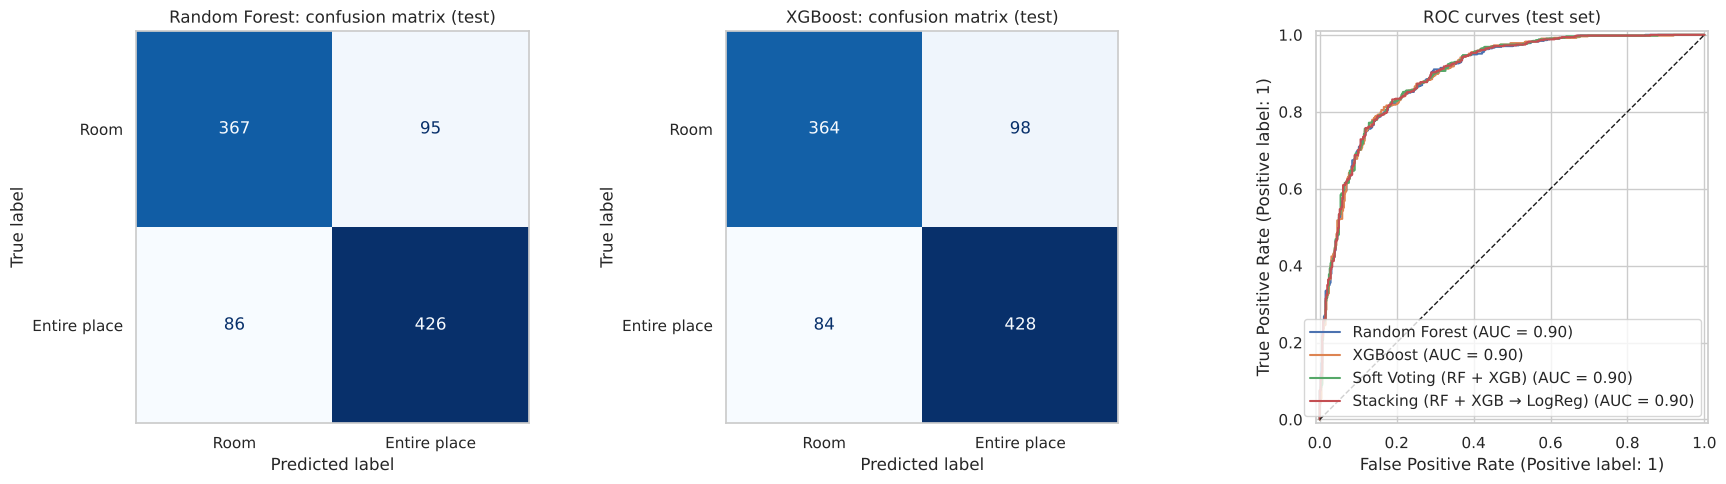

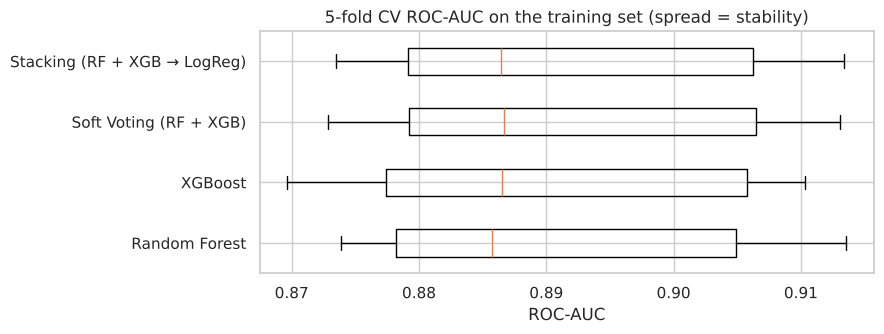

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes[:2], ["Random Forest", "XGBoost"]):
    ConfusionMatrixDisplay.from_estimator(fitted[name], X_test, y_test, ax=ax, colorbar=False,
                                          display_labels=["Room", "Entire place"], cmap="Blues")
    ax.set_title(f"{name}: confusion matrix (test)"); ax.grid(False)
for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=axes[2], name=name)
axes[2].plot([0, 1], [0, 1], "k--", lw=1); axes[2].set_title("ROC curves (test set)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 3.5))
plt.boxplot(list(cv_scores.values()), vert=False)
plt.yticks(range(1, len(cv_scores) + 1), list(cv_scores.keys()))
plt.title("5-fold CV ROC-AUC on the training set (spread = stability)")
plt.xlabel("ROC-AUC"); plt.tight_layout(); plt.show()

In [20]:
for name in ["Random Forest", "XGBoost"]:
    print(f"=== {name} ===")
    print(classification_report(y_test, fitted[name].predict(X_test),
                                target_names=["Room", "Entire place"], digits=3))

=== Random Forest ===


              precision    recall  f1-score   support

        Room      0.810     0.794     0.802       462
Entire place      0.818     0.832     0.825       512

    accuracy                          0.814       974
   macro avg      0.814     0.813     0.813       974
weighted avg      0.814     0.814     0.814       974

=== XGBoost ===


              precision    recall  f1-score   support

        Room      0.812     0.788     0.800       462
Entire place      0.814     0.836     0.825       512

    accuracy                          0.813       974
   macro avg      0.813     0.812     0.812       974
weighted avg      0.813     0.813     0.813       974



### 9.1 Error analysis: what does the model get wrong?
Below are the soft-voting ensemble's **most confident mistakes** on the test set (the predicted probability is far from 0.5, yet the prediction is wrong).

In [21]:
vote = fitted["Soft Voting (RF + XGB)"]
p = vote.predict_proba(X_test)[:, 1]
errors = data.loc[X_test.index, ["name", "numberOfGuests", "stars", "roomType"]].assign(
    **{"P(entire place)": p.round(2)})
errors = errors[(p >= 0.5) != y_test.values]
print(f"{len(errors)} of {len(X_test)} test listings misclassified ({len(errors)/len(X_test):.1%})")
errors.assign(confidence=(errors["P(entire place)"] - 0.5).abs()) \
      .sort_values("confidence", ascending=False).drop(columns="confidence").head(15)

182 of 974 test listings misclassified (18.7%)


,name,numberOfGuests,stars,roomType,P(entire place)
4333,Deluxe Double Room with Garden View,2,NaN,Entire home,0.04
2904,Villa Sihinanadi Close to the beach,5,4.88,Private room in villa,0.94
3172,Luxury Smart villa in kandy with pool n jacuzzi,10,4.88,Private room in bed and breakfast,0.93
760,Abode Ahangama - whole villa,8,4.88,Room in boutique hotel,0.93
329,Stunning Tekanda Lodge near Ahangama,2,NaN,Entire villa,0.09
411,Tea Heights,6,5.00,Room in boutique hotel,0.90
1735,Beautiful Boutique Location,2,NaN,Entire home,0.10
779,Beachside Luxury Suite - Max Wadiya Boutique Hotel,2,NaN,Entire rental unit,0.10
719,One Room Exclusive by Ceilao Villas,2,NaN,Entire villa,0.10
1369,Lotus Eco Villa,4,5.00,Private room in nature lodge,0.89


## 10. What the models learned (feature importance)

Built-in importances are biased in different ways: RF's impurity importance favours continuous, high-cardinality features, and XGBoost's *gain* favours features used in early, decisive splits. **Permutation importance** on the test set (how much ROC-AUC drops when one feature is shuffled) is model-agnostic, so it is shown for both models side by side.

Drop in test ROC-AUC when each RAW input is shuffled:


,Random Forest,XGBoost
name,0.2140,0.1970
numberOfGuests,0.0987,0.1107
stars,0.0086,0.0103


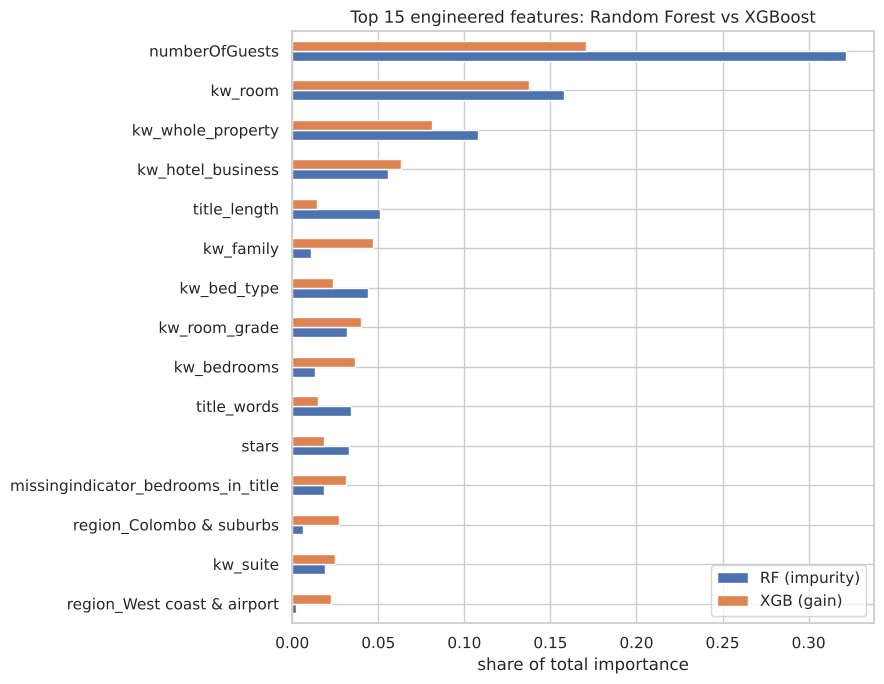

In [22]:
def permutation_table(pipe):
    r = permutation_importance(pipe, X_test, y_test, scoring="roc_auc",
                               n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    return pd.Series(r.importances_mean, index=X_test.columns)

# Permutation on the RAW inputs (name, guests, stars) shows which input field matters
raw_perm = pd.DataFrame({n: permutation_table(fitted[n]) for n in ["Random Forest", "XGBoost"]})
print("Drop in test ROC-AUC when each RAW input is shuffled:")
display(raw_perm.round(4))

# Engineered-feature level: built-in importances from each fitted model
def builtin_importance(name):
    pipe = fitted[name]
    names = pipe.named_steps["prep"].get_feature_names_out()
    names = [n.split("__", 1)[1] for n in names]
    return pd.Series(pipe.named_steps["model"].feature_importances_, index=names)

imp = pd.DataFrame({"RF (impurity)": builtin_importance("Random Forest"),
                    "XGB (gain)": builtin_importance("XGBoost")})
imp = imp.div(imp.sum())               # normalise to 100% for comparison
top = imp.loc[imp.max(axis=1).sort_values(ascending=False).index[:15]]
top.iloc[::-1].plot.barh(figsize=(9, 7), color=["#4C72B0", "#DD8452"])
plt.title("Top 15 engineered features: Random Forest vs XGBoost")
plt.xlabel("share of total importance"); plt.tight_layout(); plt.show()

## 11. Interpretation, strengths and limitations

### 11.1 What the results say

**1. Both models work well, and equally well.** Random Forest and XGBoost both reach **test ROC-AUC ≈ 0.898 and accuracy ≈ 81%**. Always guessing the majority class ("Entire place") would give only 52.6% accuracy. Their CV means (0.8912 vs 0.8899) differ by about **one tenth of the fold-to-fold standard deviation (≈ 0.015)**, so neither is genuinely better on this data.

**2. The ensembles did not add accuracy, and the reason is visible.** Soft voting and stacking reach CV 0.8917 (+0.0005). An ensemble only helps when its members make *different* mistakes, but the two confusion matrices are almost identical (RF 367/95/86/426, XGB 364/98/84/428). Both models learned the same rules from the same title keywords, so averaging them changes little.

**3. Overfitting is under control.** Train vs test accuracy: RF 85.6% → 81.4% (gap 4.2 points); XGBoost 83.7% → 81.3% (gap 2.4 points). The designed regularisation (RF depth cap 12 and minimum leaf size 2; XGB learning rate 0.03, depth 4 and L2 = 5) did its job. A fully grown forest would score close to 100% on the training set.

**4. What drives the predictions, and whether it makes sense locally.**
* Shuffling the **title** drops test ROC-AUC by **≈ 0.20–0.21**, shuffling **guest count** by **≈ 0.10–0.11**, and shuffling the **star rating** by only **≈ 0.01**.
* The strongest engineered features are `numberOfGuests`, `kw_room`, `kw_whole_property` and `kw_hotel_business`. This matches how Sri Lankan tourism works: a "Deluxe Double Room" in a Galle boutique hotel sleeps 2, while a South-coast villa rented whole sleeps 6–16 (median 6 guests for entire places vs 2 for rooms).
* **RF and XGBoost weight features differently.** RF gives about 32% of its importance to `numberOfGuests`, because impurity importance favours continuous features with many possible split points. XGBoost spreads its gain more evenly across the keyword flags and picks up regional patterns, e.g. `region_Colombo & suburbs`, where listings are mostly whole apartments and condos.
* **The rating carries almost no signal**, which agrees with §4: how well a stay is rated says nothing about whether it is a room or a whole place. Imputing it with median + indicator was still the right way to handle the 58% missing values; it just turned out to be a weak feature.

**5. The errors (§9.1) fall into three groups:**
* **Titles with no type information:** "Tea Heights", "Elephants Nest", "Beautiful Boutique Location". No title-based model can classify these reliably.
* **"Villa" used as a brand name:** many Sri Lankan guesthouses call themselves "*X* Villa" but rent individual rooms (e.g. "Villa Sihinanadi Close to the beach" is a private room in a villa).
* **Label noise from hosts choosing the wrong Airbnb type:** "Abode Ahangama – whole villa" is labelled *Room in boutique hotel*, and "Deluxe Double Room with Garden View" is labelled *Entire home*. Here the model is arguably right and the label is wrong. This noise puts a ceiling on achievable accuracy.

### 11.2 Strengths and limitations of each model

| | **Random Forest** (bagging) | **XGBoost** (boosting) |
|---|---|---|
| **Strengths on this data** | • Robust with little tuning: the quick, untuned forest in §4 already scored 0.892 CV ROC-AUC, about the same as the tuned one (0.891), so it is hard to configure badly.<br>• Averaging many de-correlated trees makes it tolerant of the noisy labels above.<br>• Trees are independent, so they train in parallel. | • **Smallest overfitting gap (2.4 points)**, thanks to shrinkage, L2 regularisation and row/column subsampling.<br>• **Fastest to train (≈ 0.9 s) and to predict (≈ 0.2 ms per listing)**, with a compact model.<br>• Handles missing values natively and learns which branch NaNs should follow. |
| **Limitations on this data** | • Larger train–test gap (4.2 points): deep trees partly memorise unique titles.<br>• Bigger model file and slower predictions (500 trees of depth up to 12).<br>• Impurity importance is biased toward `numberOfGuests`, so permutation importance was needed to interpret it fairly. | • More hyperparameters that interact (learning rate × number of trees × depth), so it needs careful, CV-based tuning.<br>• Trees are built sequentially, so they cannot be parallelised across trees.<br>• Boosting keeps trying to fix mislabelled examples. The low learning rate limits this, but it is a known weakness with noisy labels.<br>• No accuracy gain over RF on a small, keyword-driven dataset. |
| **Soft Voting** | + The lecturer's pipeline; smoother, better-calibrated probabilities for the front end. − Little gain when the base models agree; costs two models at prediction time. | |
| **Stacking** | + Learns how much to trust each model instead of weighting them equally. − About 4× the training time (≈ 8 s, because of cross-validation inside cross-validation), harder to explain, and no measurable gain here. | |

### 11.3 Limitations of the study
* **Only three raw inputs.** Everything else is engineered from the title with English keyword lists, which miss Sinhala and Tamil transliterations such as *niwasa*, *gedara* and *illam*.
* **A region could be detected in only about 30% of titles**; the rest are "Unknown".
* **Labels are host-chosen Airbnb categories** and contain noise (see §11.1, point 5).
* The data is an Airbnb snapshot weighted toward tourist areas, so performance on ikman.lk or Facebook ads would need to be checked on a sample of those ads.

**Ideas for the final assignment:** TF-IDF or CatBoost text features on the title instead of hand-made keyword lists, Sinhala and Tamil keywords, LightGBM and CatBoost in the comparison, and scraping prices so a regression target becomes possible.

## 12. Export the final model (.pkl)

The final model is chosen using the **cross-validation results on the training data**, not the test score, so the test set stays an honest, unbiased estimate. If the CV means of all models are closer together than the fold-to-fold standard deviation, the difference is noise, and the soft-voting ensemble is exported (the reasons are in the code comments). The whole pipeline (feature builder → imputer/scaler/encoder → model) is pickled, so the front end only needs to pass raw fields.

In [23]:
cv_summary = pd.DataFrame({"mean": {n: s.mean() for n, s in cv_scores.items()},
                           "std":  {n: s.std()  for n, s in cv_scores.items()}})
best_mean = cv_summary["mean"].max()
spread = best_mean - cv_summary["mean"].min()
print(cv_summary.round(4))
print(f"\nGap between best and worst CV mean: {spread:.4f}  vs  fold-to-fold std ≈ {cv_summary['std'].mean():.4f}")

# Rule: if all models are within one CV standard deviation of the best, they are a statistical tie.
# In that case export the soft-voting ensemble: it is the pipeline the activity asks for,
# it averages two different model families (more robust to unusual titles),
# and it trains about 4x faster than stacking for the same score.
if spread < cv_summary["std"].mean():
    final_name = "Soft Voting (RF + XGB)"
    print("→ Statistical tie: exporting", final_name)
else:
    final_name = cv_summary["mean"].idxmax()
    print("→ Clear winner by CV ROC-AUC:", final_name)
final_model = fitted[final_name]

bundle = {
    "model": final_model,
    "model_name": final_name,
    "input_fields": ["name", "numberOfGuests", "stars"],
    "classes": {0: "Room", 1: "Entire place"},
    "test_metrics": results.loc[final_name, ["Test ROC-AUC", "Test accuracy", "F1"]].round(4).to_dict(),
}
with open("model.pkl", "wb") as f:
    pickle.dump(bundle, f)

# Sanity check: reload from disk and predict
with open("model.pkl", "rb") as f:
    reloaded = pickle.load(f)
assert (reloaded["model"].predict(X_test) == final_model.predict(X_test)).all()
print("model.pkl saved and reloaded successfully. Test metrics:", bundle["test_metrics"])

                                mean     std
Random Forest                 0.8912  0.0154
XGBoost                       0.8899  0.0158
Soft Voting (RF + XGB)        0.8917  0.0156
Stacking (RF + XGB → LogReg)  0.8917  0.0155

Gap between best and worst CV mean: 0.0018  vs  fold-to-fold std ≈ 0.0156
→ Statistical tie: exporting Soft Voting (RF + XGB)


model.pkl saved and reloaded successfully. Test metrics: {'Test ROC-AUC': 0.8994, 'Test accuracy': 0.8131, 'F1': 0.8247}


## 13. Inference on a single sample

### 13.1 The held-out listing
This row was removed in §6.1, **before** the train/test split, so no model has ever seen it.

In [24]:
model = reloaded["model"]
sample = holdout[["name", "numberOfGuests", "stars"]]
p_entire = model.predict_proba(sample)[0, 1]
pred_label = reloaded["classes"][int(p_entire >= 0.5)]
true_label = reloaded["classes"][int(holdout["target"].iloc[0])]

print("Input fed to the model:")
display(sample)
print(f"Actual Airbnb roomType : {holdout['roomType'].iloc[0]}  →  {true_label}")
print(f"Predicted              : {pred_label}  (P(entire place) = {p_entire:.1%})")
print("Correct!" if pred_label == true_label else "Incorrect")

Input fed to the model:


,name,numberOfGuests,stars
3477,Kirinuga Boutique Retreat | Private room,2,4.71


Actual Airbnb roomType : Room in boutique hotel  →  Room
Predicted              : Room  (P(entire place) = 3.2%)
Correct!


### 13.2 Brand-new listings typed in by hand (as a host would on ikman.lk)

In [25]:
new_listings = pd.DataFrame([
    {"name": "Deluxe Double Room with Sea View - Mirissa", "numberOfGuests": 2, "stars": None},
    {"name": "Luxury 4 Bedroom Villa with Private Pool, Bentota", "numberOfGuests": 8, "stars": 4.95},
    {"name": "Cozy apartment in Colombo 7 with kitchen", "numberOfGuests": 3, "stars": None},
    {"name": "Ella Rock View Homestay - Family Room with breakfast", "numberOfGuests": 4, "stars": 4.8},
])
probs = model.predict_proba(new_listings)[:, 1]
new_listings["prediction"] = np.where(probs >= 0.5, "Entire place", "Room")
new_listings["P(entire place)"] = (probs * 100).round(1).astype(str) + "%"
new_listings

,name,numberOfGuests,stars,prediction,P(entire place)
0,Deluxe Double Room with Sea View - Mirissa,2,NaN,Room,3.4%
1,"Luxury 4 Bedroom Villa with Private Pool, Bentota",8,4.95,Entire place,97.6%
2,Cozy apartment in Colombo 7 with kitchen,3,NaN,Entire place,74.3%
3,Ella Rock View Homestay - Family Room with breakfast,4,4.80,Room,6.8%


## 14. Front end (GenAI-generated)

The pickle is served by a small **Streamlit** app (`app.py`) with text boxes for the three fields. It loads `model.pkl`, shows the prediction and probability, and lists which title signals it detected. Run it with:

```bash
pip install -r requirements.txt
streamlit run app.py
```

**Prompt given to the GenAI assistant to generate the front end:**

> I have trained a scikit-learn ML model and saved it with pickle as `model.pkl`. The pickle is a dictionary: `model` is a full sklearn Pipeline (it imports a custom transformer from `features.py`, which sits in the same folder), `classes` maps 0 → "Room" and 1 → "Entire place", and `test_metrics` holds the accuracy, F1 and ROC-AUC. The pipeline takes a pandas DataFrame with exactly these raw columns: `name` (text: the listing title), `numberOfGuests` (integer 1–16) and `stars` (float 1–5, or empty/NaN if the listing has no rating yet). Please write a Streamlit app (`app.py`) that loads the pickle once with caching, shows text boxes / number inputs for the three fields (a checkbox for "no rating yet" that sends NaN), a Predict button, and displays the predicted class with its probability as a progress bar. Also show the model name and test metrics in the sidebar, provide 3 example Sri Lankan listings the user can click to auto-fill, and show which keywords and region `features.engineer_features` detected in the title. Keep it in one file and add a `requirements.txt`.

## 15. Conclusion

* Using a local Sri Lankan Airbnb dataset (4,870 listings after cleaning), a listing's **title + guest capacity (+ rating)** is enough to tell an **entire place from a room with ≈ 81% accuracy and ROC-AUC ≈ 0.90**.
* **Random Forest and XGBoost performed the same** (CV ROC-AUC 0.891 vs 0.890). XGBoost overfit less and was faster; Random Forest was more forgiving to tune and more tolerant of noisy labels.
* **Soft voting and stacking added only +0.0005 CV ROC-AUC**, because both base models make the same mistakes. The soft-voting ensemble was exported as `model.pkl`, since all models were tied and it is the simplest and most robust of the ensembles.
* The remaining errors come mostly from **titles with no type information and from mislabelled listings**. Better text features and local-language keywords, not a different algorithm, are the next step.